<a href="https://colab.research.google.com/github/hxnzlhxrx/Projeto_Final_Toti_Armazem/blob/main/Projeto_Final_Toti_Armazem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto final Toti | Armazém

Neste projeto, quero responder a duas perguntas simples: **quais armazéns estão mais cheios?** e **onde está concentrado o valor das caixas?** Depois, vou usar as respostas para montar um painel no Power BI.

Os dados vêm do [exercício de armazéns do Wikibooks](https://en.wikibooks.org/wiki/SQL_Exercises/The_warehouse), indicado nas orientações da Toti. Os nomes foram adaptados para português. É um conjunto didático com 5 armazéns e 11 caixas.

Para acompanhar, execute os campos na ordem. Quando o Colab pedir, envie os arquivos `armazens.csv` e `caixas.csv`.


## 1. Abrir os arquivos

Começo importando as bibliotecas que vamos usar. Depois envio os dois CSV exportados do banco de dados.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Selecione armazens.csv e caixas.csv ao mesmo tempo.
files.upload()


Saving armazens.csv to armazens.csv
Saving caixas.csv to caixas.csv


{'armazens.csv': b'\xef\xbb\xbfcodigo,cidade,capacidade\r\n1,Chicago,3\r\n2,Chicago,4\r\n3,New York,7\r\n4,Los Angeles,2\r\n5,San Francisco,8\r\n',
 'caixas.csv': b'\xef\xbb\xbfcodigo,conteudo,valor,codigo_armazem\r\n0MN7,Pedras,180.0,3\r\n4H8P,Pedras,250.0,1\r\n4RT3,Tesouras,190.0,4\r\n7G3H,Pedras,200.0,1\r\n8JN6,Pap\xc3\xa9is,75.0,1\r\n8Y6U,Pap\xc3\xa9is,50.0,3\r\n9J6F,Pap\xc3\xa9is,175.0,2\r\nLL08,Pedras,140.0,4\r\nP0H6,Tesouras,125.0,1\r\nP2T6,Tesouras,150.0,2\r\nTU55,Pap\xc3\xa9is,90.0,5\r\n'}

In [2]:
armazens = pd.read_csv('armazens.csv')
caixas = pd.read_csv('caixas.csv')

print('Armazéns:', len(armazens), '| Caixas:', len(caixas))
display(armazens.head())
display(caixas.head())


Armazéns: 5 | Caixas: 11


,codigo,cidade,capacidade
0,1,Chicago,3
1,2,Chicago,4
2,3,New York,7
3,4,Los Angeles,2
4,5,San Francisco,8


,codigo,conteudo,valor,codigo_armazem
0,0MN7,Pedras,180.0,3
1,4H8P,Pedras,250.0,1
2,4RT3,Tesouras,190.0,4
3,7G3H,Pedras,200.0,1
4,8JN6,Papéis,75.0,1


## 2. Conhecer os dados

Antes de calcular qualquer coisa, verifico se há campos vazios ou códigos repetidos. Isso ajuda a perceber se os arquivos precisam de correções.


In [3]:
print('Campos vazios em armazéns:')
print(armazens.isna().sum())
print()
print('Campos vazios em caixas:')
print(caixas.isna().sum())

print()
print('Códigos repetidos em armazéns:', armazens['codigo'].duplicated().sum())
print('Códigos repetidos em caixas:', caixas['codigo'].duplicated().sum())


Campos vazios em armazéns:
codigo        0
cidade        0
capacidade    0
dtype: int64

Campos vazios em caixas:
codigo            0
conteudo          0
valor             0
codigo_armazem    0
dtype: int64

Códigos repetidos em armazéns: 0
Códigos repetidos em caixas: 0


Neste conjunto de exemplo, não há campos vazios nem códigos repetidos. Por isso, vou apenas deixar os nomes mais claros e conferir os tipos numéricos.


## 3. Preparar as tabelas

O código de cada armazém liga as duas tabelas. Chamo essa coluna de `armazem_id` em ambas para facilitar a análise e a relação no Power BI.


In [4]:
armazens_tratados = armazens.rename(columns={'codigo': 'armazem_id'}).copy()
caixas_tratadas = caixas.rename(columns={
    'codigo': 'caixa_id',
    'codigo_armazem': 'armazem_id'
}).copy()

# Retiro espaços extras e garanto que os números sejam reconhecidos como números.
armazens_tratados['cidade'] = armazens_tratados['cidade'].str.strip()
caixas_tratadas['conteudo'] = caixas_tratadas['conteudo'].str.strip()
armazens_tratados['capacidade'] = pd.to_numeric(armazens_tratados['capacidade'])
caixas_tratadas['valor'] = pd.to_numeric(caixas_tratadas['valor'])

display(armazens_tratados.head())
display(caixas_tratadas.head())


,armazem_id,cidade,capacidade
0,1,Chicago,3
1,2,Chicago,4
2,3,New York,7
3,4,Los Angeles,2
4,5,San Francisco,8


,caixa_id,conteudo,valor,armazem_id
0,0MN7,Pedras,180.0,3
1,4H8P,Pedras,250.0,1
2,4RT3,Tesouras,190.0,4
3,7G3H,Pedras,200.0,1
4,8JN6,Papéis,75.0,1


## 4. Ver a ocupação de cada armazém

Conto as caixas e somo seus valores por armazém. Depois junto esse resultado à tabela de armazéns. Uso uma junção à esquerda para manter também um armazém que esteja vazio.


In [5]:
por_armazem = caixas_tratadas.groupby('armazem_id').agg(
    quantidade_caixas=('caixa_id', 'count'),
    valor_total=('valor', 'sum')
).reset_index()

resumo = armazens_tratados.merge(por_armazem, on='armazem_id', how='left')
resumo[['quantidade_caixas', 'valor_total']] = resumo[
    ['quantidade_caixas', 'valor_total']
].fillna(0)
resumo['quantidade_caixas'] = resumo['quantidade_caixas'].astype(int)
resumo['ocupacao'] = resumo['quantidade_caixas'] / resumo['capacidade']
resumo['situacao'] = np.where(
    resumo['ocupacao'] > 1, 'Acima da capacidade', 'Dentro da capacidade'
)

display(resumo)


,armazem_id,cidade,capacidade,quantidade_caixas,valor_total,ocupacao,situacao
0,1,Chicago,3,4,650.0,1.333333,Acima da capacidade
1,2,Chicago,4,2,325.0,0.500000,Dentro da capacidade
2,3,New York,7,2,230.0,0.285714,Dentro da capacidade
3,4,Los Angeles,2,2,330.0,1.000000,Dentro da capacidade
4,5,San Francisco,8,1,90.0,0.125000,Dentro da capacidade


In [6]:
total_caixas = len(caixas_tratadas)
capacidade_total = resumo['capacidade'].sum()
valor_total = caixas_tratadas['valor'].sum()
armazens_excedidos = (resumo['ocupacao'] > 1).sum()

print('Total de caixas:', total_caixas)
print('Capacidade total:', capacidade_total)
print('Taxa de ocupação geral:',
      f'{100 * total_caixas / capacidade_total:.1f}%'.replace('.', ','))
print('Armazéns acima da capacidade:', armazens_excedidos)
print('Valor total registrado (US$):', valor_total)


Total de caixas: 11
Capacidade total: 24
Taxa de ocupação geral: 45,8%
Armazéns acima da capacidade: 1
Valor total registrado (US$): 1625.0


## 5. Criar gráficos

A taxa geral ajuda a resumir o conjunto, mas pode esconder um problema localizado. Por isso, mostro a ocupação de cada armazém e marco a linha de 100%.


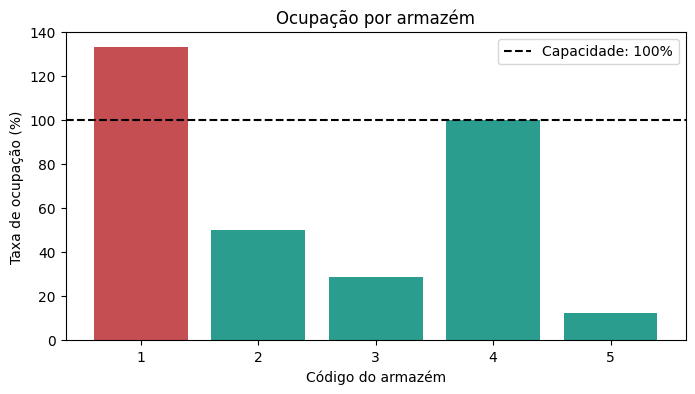

In [7]:
cores = np.where(resumo['ocupacao'] > 1, '#C44E52', '#2A9D8F')

plt.figure(figsize=(8, 4))
plt.bar(resumo['armazem_id'].astype(str), resumo['ocupacao'] * 100, color=cores)
plt.axhline(100, color='black', linestyle='--', label='Capacidade: 100%')
plt.title('Ocupação por armazém')
plt.xlabel('Código do armazém')
plt.ylabel('Taxa de ocupação (%)')
plt.legend()
plt.show()


Agora relaciono as caixas às cidades e comparo o valor guardado em cada uma.


,valor
cidade,
Chicago,975.0
Los Angeles,330.0
New York,230.0
San Francisco,90.0


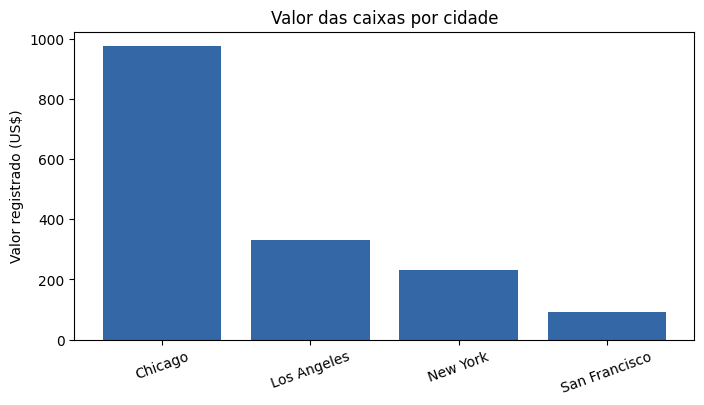

In [8]:
caixas_com_cidade = caixas_tratadas.merge(
    armazens_tratados[['armazem_id', 'cidade']], on='armazem_id'
)
valor_por_cidade = caixas_com_cidade.groupby('cidade')['valor'].sum()
valor_por_cidade = valor_por_cidade.sort_values(ascending=False)

display(valor_por_cidade)

plt.figure(figsize=(8, 4))
plt.bar(valor_por_cidade.index, valor_por_cidade.values, color='#3467A5')
plt.title('Valor das caixas por cidade')
plt.ylabel('Valor registrado (US$)')
plt.xticks(rotation=20)
plt.show()


## 6. O que os dados sugerem?

1. **Rever o armazém 1.** Ele guarda 4 caixas, mas comporta 3. O armazém 2, também em Chicago, tem duas vagas livres. Vale estudar a transferência de uma caixa.
2. **Acompanhar cada armazém separadamente.** A ocupação geral é de 45,8%, mas esse número não mostra que um armazém já passou da capacidade.
3. **Observar a concentração de valor em Chicago.** A cidade reúne US$ 975 dos US$ 1.625 registrados, ou 60%. Antes de mudar a operação, vale conferir como as caixas de maior valor estão distribuídas.

Essas são recomendações iniciais. Como os dados não têm datas, vendas, movimentações ou custos, não posso concluir nada sobre tendências, giro de estoque ou lucro. Na apresentação, cada integrante deve explicar três recomendações apoiadas nos resultados.


## 7. Preparar os arquivos do Power BI

Salvo as duas tabelas tratadas em CSV. No Power BI, vou relacionar `armazens_tratados[armazem_id]` com `caixas_tratadas[armazem_id]`. O arquivo ZIP facilita baixar as duas tabelas de uma vez.


In [9]:
from pathlib import Path
from zipfile import ZipFile

pasta = Path('saida_powerbi')
pasta.mkdir(exist_ok=True)
armazens_tratados.to_csv(pasta / 'armazens_tratados.csv', index=False, encoding='utf-8-sig')
caixas_tratadas.to_csv(pasta / 'caixas_tratadas.csv', index=False, encoding='utf-8-sig')

with ZipFile('saida_powerbi.zip', 'w') as pacote:
    pacote.write(pasta / 'armazens_tratados.csv', arcname='armazens_tratados.csv')
    pacote.write(pasta / 'caixas_tratadas.csv', arcname='caixas_tratadas.csv')

files.download('saida_powerbi.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>